<a href="https://colab.research.google.com/github/gnperdue/SaturdayMorningQuantum/blob/main/QuantumComputing_QEC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Computing in 2 Hours*

## Companion notebook: quantum error correction

*Actually learning programming in a short period of time is more challenging than you might think...

<img src="images/1fl5yi6bbpzz.png" height=500>

**To use this notebook: click a cell to edit it, and press Shift+Return to run it (code or text).**

This is the companion to the main lecture notebook, [`QuantumComputing.ipynb`](https://colab.research.google.com/github/gnperdue/SaturdayMorningQuantum/blob/main/QuantumComputing.ipynb). It builds on what the main notebook teaches (qubits, gates as matrices, tensor products, no cloning and QASM), so work through that first, then run the setup cell below. It has two parts:

1. **Quantum error correction:** the repetition code, phase flips, the surface code, its threshold, and how big a code needs to be.
2. **From error correction to fault-tolerant computing:** why the Clifford gates are nearly free, how a $T$ gate is made from a magic state, and $T$ factories.

In [1]:
#@title "Software Setup [Run this cell with Shift+Enter!]"
try:
    import numpy as np
    import matplotlib.pyplot as plt
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit_aer import AerSimulator
    import cirq
    import stim
    import pymatching
except ImportError:
    import subprocess, sys
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install",
         "qiskit==2.3.1", "qiskit-aer==0.17.2", "cirq-core==1.6.1",
         "stim==1.15.0", "pymatching==2.4.0", "-q"]
    )
    import numpy as np
    import matplotlib.pyplot as plt
    import qiskit
    from qiskit import QuantumCircuit
    from qiskit_aer import AerSimulator
    import cirq
    import stim
    import pymatching

print(f"NumPy {np.__version__}")
print(f"Qiskit {qiskit.__version__}")
print(f"Cirq {cirq.__version__}")
print(f"Stim {stim.__version__}")
print(f"PyMatching {pymatching.__version__}")

NumPy 2.4.3
Qiskit 2.3.1
Cirq 1.6.1
Stim 1.15.0
PyMatching 2.4.0


This notebook was last tested with NumPy 2.4.3, Qiskit 2.3.1, Qiskit Aer 0.17.2, Cirq 1.6.1, Stim 1.15.0 and PyMatching 2.4.0. When the setup cell has to install software (as on Colab), it installs exactly those versions of Qiskit, Qiskit Aer, Cirq, Stim and PyMatching, so your results should match ours.

## Quantum Error Correction

### Why error correction?

The main notebook noted that real quantum hardware is noisy: gates are imperfect and qubits interact with their environment. Classical computers face noise too, but they solve it with redundancy: store each bit multiple times and take a majority vote. This works because classical bits can be freely copied.

For a thorough introduction to both classical and quantum error correction, see Girvin's [lecture notes](https://arxiv.org/abs/2111.08894).

### Why is quantum error correction hard?

Three features of quantum mechanics make error correction fundamentally harder than in the classical case:

1. **No cloning** — as the main notebook showed, we can't copy an arbitrary qubit, so naive redundancy is out.
2. **Measurement destroys superpositions** — if we measure a qubit to check for errors, we collapse it and lose the computation.
3. **Errors are continuous** — a classical bit flips from 0 to 1, but a qubit can rotate by any small angle. We need to correct a continuum of possible errors.

The key insight of quantum error correction is that we can detect errors _indirectly_ by measuring **correlations** between qubits (called _stabilizers_ or _parity checks_) without ever learning the encoded state itself.

### The repetition code

The simplest error-correcting code — classical or quantum — is the **repetition code**. We encode one logical bit using multiple physical bits. If noise flips one of them, a majority vote recovers the original.

The quantum version protects against **bit-flip errors** (X errors). We encode one logical qubit in three physical qubits:

$$|0_L\rangle = |000\rangle, \quad |1_L\rangle = |111\rangle$$

To detect errors without measuring the data qubits directly, we measure **parity checks** between neighboring pairs. These tell us whether adjacent qubits agree or disagree — without revealing what value they hold.

The parity checks (stabilizers) for the 3-qubit repetition code are:

$$Z_0 Z_1 \quad \text{and} \quad Z_1 Z_2$$

Each measures whether a pair of qubits is in the same state (+1) or different states (−1). The pair of measurement outcomes is called the **syndrome**. From the syndrome, we can deduce which qubit (if any) was flipped:

| Syndrome ($Z_0Z_1$, $Z_1Z_2$) | Interpretation |
|:---:|:---|
| +1, +1 | No error |
| −1, +1 | Error on qubit 0 |
| −1, −1 | Error on qubit 1 |
| +1, −1 | Error on qubit 2 |

The notation $Z_0 Z_1$ is shorthand — since we have three qubits, the full operator is $Z_0 \otimes Z_1 \otimes I_2$ (identity on the third qubit). The $Z$ gate is $\begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$: it leaves $|0\rangle$ alone and flips the sign of $|1\rangle$. Using the tensor product rules from the main notebook:

$$
Z_0 \otimes Z_1 \otimes I_2 =
\begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} \otimes
\begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix} \otimes
\begin{pmatrix} 1 & 0 \\ 0 & 1 \end{pmatrix} =
\begin{pmatrix}
1 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & -1 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & -1 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & -1 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & -1 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1
\end{pmatrix}
$$

This is a diagonal matrix with $+1$ on entries where qubits 0 and 1 agree (both $|0\rangle$ or both $|1\rangle$) and $-1$ where they disagree. That's exactly the parity check we need — and the identity on qubit 2 means we learn nothing about it.

To see this in action, apply the operator to $|000\rangle$ (qubits 0 and 1 agree):

$$
(Z_0 \otimes Z_1 \otimes I_2)|000\rangle =
\begin{pmatrix} 1 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \end{pmatrix}
= +1 |000\rangle
$$

Now apply it to $|010\rangle$ (qubits 0 and 1 disagree):

$$
(Z_0 \otimes Z_1 \otimes I_2)|010\rangle =
\begin{pmatrix} 0 \\ 0 \\ -1 \\ 0 \\ 0 \\ 0 \\ 0 \\ 0 \end{pmatrix}
= -1 |010\rangle
$$

The $+1$ or $-1$ eigenvalue tells us the parity without revealing the actual qubit values — exactly what we need for error detection.

Before we simulate, let's look at the circuit for measuring the two stabilizers. We use [Cirq](https://quantumai.google/cirq) to draw it:

In [2]:
# Repetition code stabilizer measurement circuit
q0, q1, q2 = cirq.LineQubit.range(3)          # data qubits
a0, a1 = cirq.NamedQubit('s01'), cirq.NamedQubit('s12')  # syndrome ancillas

rep_code_circuit = cirq.Circuit([
    # Stabilizer Z0*Z1: parity of q0 and q1 into ancilla s01
    cirq.Moment([cirq.CNOT(q0, a0), cirq.CNOT(q1, a1)]),
    cirq.Moment([cirq.CNOT(q1, a0), cirq.CNOT(q2, a1)]),
    # Measure ancillas
    cirq.Moment([cirq.measure(a0, key='Z0Z1'),
                 cirq.measure(a1, key='Z1Z2')]),
])

print(rep_code_circuit)

        ┌──┐   ┌──┐
0: ──────@────────────────────────
         │
1: ──────┼@─────@─────────────────
         ││     │
2: ──────┼┼─────┼@────────────────
         ││     ││
s01: ────X┼─────X┼────M('Z0Z1')───
          │      │
s12: ─────X──────X────M('Z1Z2')───
        └──┘   └──┘


Let's simulate this with [Stim](https://github.com/quantumlib/Stim), a fast stabilizer circuit simulator designed for quantum error correction:

In [3]:
# 3-qubit repetition code with Stim
repetition_code = stim.Circuit('''
    # Data qubits: 0, 1, 2
    # Ancilla qubits: 3, 4

    # Introduce a single bit-flip error on qubit 1
    X_ERROR(1.0) 1

    # Stabilizer Z0*Z1: CNOT from data qubits 0,1 into ancilla 3
    CX 0 3
    CX 1 3
    # Stabilizer Z1*Z2: CNOT from data qubits 1,2 into ancilla 4
    CX 1 4
    CX 2 4

    # Measure ancillas to get the syndrome
    M 3 4
''')

sampler = repetition_code.compile_sampler()
syndrome = sampler.sample(shots=1)
print(f'Syndrome: {syndrome[0].astype(int)}')
print()
s0, s1 = syndrome[0][0], syndrome[0][1]
if s0 and s1:
    print('Both stabilizers triggered -> error on qubit 1 (middle)')
elif s0:
    print('First stabilizer triggered -> error on qubit 0')
elif s1:
    print('Second stabilizer triggered -> error on qubit 2')
else:
    print('No stabilizers triggered -> no error detected')

Syndrome: [1 1]

Both stabilizers triggered -> error on qubit 1 (middle)


Now let's make it realistic: each qubit flips at random, with probability 10%, and we run 10,000 shots. This time we also measure the data qubits at the end, so we can compare what the decoder sees with what really happened:

In [4]:
# Repetition code with random noise
# First, a function that prints both tables (the phase-flip exercise below uses it too)
def print_both_tables(samples, physical_qubit_error):
    """Print what the decoder sees and what really happened.

    Each sample holds the two syndrome bits, then the three data bits.
    """
    shots = len(samples)
    # The decoder sees only the syndrome. For each syndrome: its guess, and the qubit it
    # flips back.
    guess_for_syndrome = {(0, 0): 'no error', (1, 0): 'flip on q0', (1, 1): 'flip on q1',
                          (0, 1): 'flip on q2'}
    qubit_to_fix = {(0, 0): None, (1, 0): 0, (1, 1): 1, (0, 1): 2}

    shots_by_syndrome = {(0, 0): 0, (1, 0): 0, (1, 1): 0, (0, 1): 0}
    shots_by_flips = [0, 0, 0, 0]     # how many shots had 0, 1, 2 or 3 flips
    errors_by_flips = [0, 0, 0, 0]    # ... and how many of those ended as a logical error
    for sample in samples:
        syndrome = (int(sample[0]), int(sample[1]))
        data = [int(sample[2]), int(sample[3]), int(sample[4])]
        shots_by_syndrome[syndrome] += 1

        flips = data[0] + data[1] + data[2]   # we started in |000>, so each 1 is a flip
        shots_by_flips[flips] += 1

        # Flip back the qubit the decoder blames, then read the logical value
        qubit = qubit_to_fix[syndrome]
        if qubit is not None:
            data[qubit] = 1 - data[qubit]
        if data[0] == 1:                      # after the correction, all three agree
            errors_by_flips[flips] += 1

    print('What the decoder sees (only the syndrome):')
    for syndrome in [(0, 0), (1, 0), (1, 1), (0, 1)]:
        count = shots_by_syndrome[syndrome]
        print(f'  syndrome {syndrome}: {count:5d} shots ({count / shots:5.1%}), '
              f'guess: {guess_for_syndrome[syndrome]}')
    print()
    print('What really happened (from the data qubits):')
    print('  flips   shots   logical errors')
    for flips in range(4):
        print(f'  {flips:5d} {shots_by_flips[flips]:7d} {errors_by_flips[flips]:10d}')
    print(f'Logical error rate: {sum(errors_by_flips) / shots:.1%}, '
          f'from a physical error rate of {physical_qubit_error:.0%} per qubit')


physical_qubit_error = 0.1   # the chance that each qubit flips
shots = 10000

noisy_repetition_code = stim.Circuit(f'''
    # The data qubits 0, 1, 2 start in |000>, the logical 0.
    # Each one flips with probability physical_qubit_error.
    X_ERROR({physical_qubit_error}) 0 1 2

    # Measure the two parity checks into the ancillas 3 and 4
    CX 0 3
    CX 1 3
    CX 1 4
    CX 2 4
    M 3 4

    # Then measure the data qubits too, to see what really happened
    M 0 1 2
''')
samples = noisy_repetition_code.compile_sampler().sample(shots=shots)
print_both_tables(samples, physical_qubit_error)

What the decoder sees (only the syndrome):
  syndrome (0, 0):  7374 shots (73.7%), guess: no error
  syndrome (1, 0):   921 shots ( 9.2%), guess: flip on q0
  syndrome (1, 1):   853 shots ( 8.5%), guess: flip on q1
  syndrome (0, 1):   852 shots ( 8.5%), guess: flip on q2

What really happened (from the data qubits):
  flips   shots   logical errors
      0    7362          0
      1    2371          0
      2     255        255
      3      12         12
Logical error rate: 2.7%, from a physical error rate of 10% per qubit


The two tables tell different stories. The decoder sees only the syndrome, and in its table every shot seems to have had at most one error. The second table shows what really happened:

* **One flip is always fixed:** the syndrome points right at it.
* **Two flips fool the code.** Flips on qubits 1 and 2 give the same syndrome as a single flip on qubit 0, so the decoder "fixes" qubit 0 and finishes turning $|000\rangle$ into $|111\rangle$: a **logical error**.
* **Three flips go unseen:** every parity check still passes.

Those two- and three-flip shots were hiding inside the decoder's rows. So the logical error rate is the chance of two or more flips, $3p^2 - 2p^3$ for a physical error rate $p$, which is close to $3p^2$ when $p$ is small: 2.8% at $p = 10\%$. That beats 10%, and the code helps whenever $p$ is below 50%. It helps most when $p$ is small, because two flips are much rarer than one. Bigger codes push the same idea further: it takes more flips to fool them.

**Exercise:** Change `physical_qubit_error` to 0.05, then to 0.01, and rerun the cell (at 0.01, raise `shots` to 100,000 so that a few logical errors show up). Each time the physical error rate halves, how much does the logical error rate drop? Why? (Hint: how many flips does it take to fool the code?)

**Challenge:** Build a five-qubit repetition code. It needs four parity checks, and it takes three flips to fool it. (A majority vote of the five data qubits makes a simple decoder.) How does its logical error rate compare with the three-qubit code's at the same physical error rate?

### Phase flips

The repetition code only catches bit flips ($X$ errors). Qubits also suffer _phase flips_ ($Z$ errors), which turn $|+\rangle$ into $|-\rangle$ and leave $|0\rangle$ and $|1\rangle$ looking unchanged. A bit-flip code can't see them at all.

The fix is to run the same code in the other basis. Encode $|+_L\rangle = |{+}{+}{+}\rangle$ and $|-_L\rangle = |{-}{-}{-}\rangle$, and measure the parities $X_0 X_1$ and $X_1 X_2$ instead of $Z_0 Z_1$ and $Z_1 Z_2$: a phase flip on one qubit now shows up in the syndrome, exactly as a bit flip did before. (A Hadamard on each qubit turns one code into the other, since $HZH = X$.)

The catch is that this code is now blind to bit flips. To catch both kinds of error at once we need both kinds of check, and that is what the surface code does.

**Exercise: build the phase-flip code.** Write a Stim circuit like the noisy repetition code above, but for phase flips, and pass its samples to `print_both_tables`. Some hints:

* `H 0 1 2` puts a Hadamard on each qubit, turning the starting $|000\rangle$ into $|{+}{+}{+}\rangle$, the logical $|+\rangle$ of the phase-flip code.
* `Z_ERROR(0.1) 0 1 2` gives each qubit a phase flip with probability 10%.
* A second `H 0 1 2` turns every phase flip into a bit flip ($HZH = X$). After it, the bit-flip code's lines (the four `CX`, then `M 3 4` and `M 0 1 2`) work unchanged.
* Or skip the second `H` and let Stim measure the parities directly: `MPP X0*X1 X1*X2` measures $X_0 X_1$ and $X_1 X_2$, and `MX 0 1 2` measures each data qubit as $+$ (0) or $-$ (1).

Do you get the same tables as for bit flips? Why? (Stim's [gate reference](https://github.com/quantumlib/Stim/blob/main/doc/gates.md) lists every instruction.)

### The surface code

The repetition code only corrects bit-flip (X) errors. Real quantum errors also include **phase flips** (Z errors) and combinations of both. The **surface code** is the leading architecture for fault-tolerant quantum computing because it corrects both types of errors simultaneously.

The surface code arranges data qubits on a 2D grid with two types of **stabilizer checks**:

- **X stabilizers** (red) detect Z errors
- **Z stabilizers** (blue) detect X errors

Each stabilizer measures the parity of its neighboring data qubits — the same idea as the repetition code, but now in two dimensions and for two error types. Let's use Stim to generate a distance-5 rotated surface code and visualize its layout:

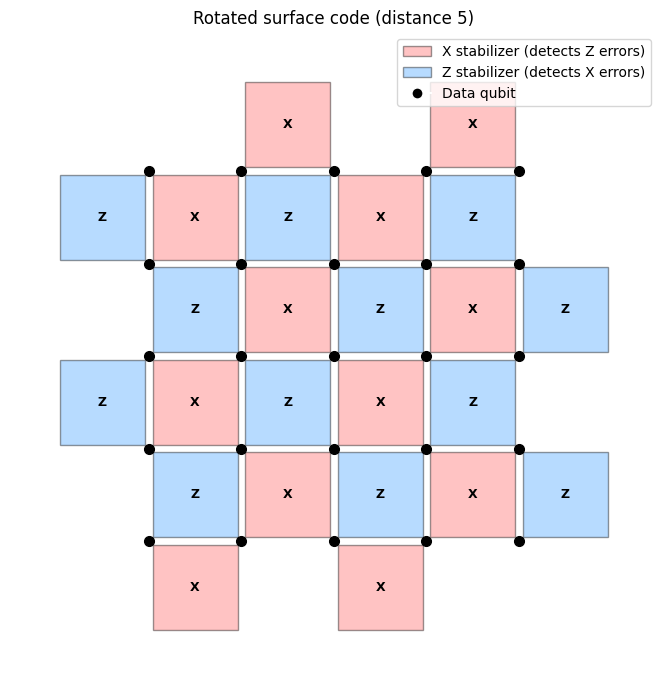

25 data qubits, 12 X stabilizers, 12 Z stabilizers


In [5]:
import re
import matplotlib.patches as mpatches

# Generate a distance-5 rotated surface code
surface_circuit = stim.Circuit.generated(
    'surface_code:rotated_memory_z',
    distance=5,
    rounds=1,
)

# Extract qubit coordinates
all_qubits = {}
for line in str(surface_circuit).split('\n'):
    m = re.match(r'QUBIT_COORDS\((\d+),\s*(\d+)\)\s+(\d+)', line)
    if m:
        x, y, idx = int(m.group(1)), int(m.group(2)), int(m.group(3))
        all_qubits[idx] = (x, y)

# Data qubits get M; ancilla qubits get MR
data_idx, measure_idx = set(), set()
for line in str(surface_circuit).split('\n'):
    if line.startswith('MR '):
        measure_idx.update(int(s) for s in line[3:].split())
    elif line.startswith('M '):
        data_idx.update(int(s) for s in line[2:].split())

# X ancillas are those that receive H gates
x_anc = set()
for line in str(surface_circuit).split('\n'):
    if line.startswith('H '):
        x_anc.update(int(s) for s in line[2:].split())

# Plot
fig, ax = plt.subplots(1, 1, figsize=(7, 7))
for idx in measure_idx:
    if idx not in all_qubits:
        continue
    x, y = all_qubits[idx]
    is_x = idx in x_anc
    color = '#FF6B6B' if is_x else '#4DA6FF'
    diamond = mpatches.RegularPolygon(
        (x, y), numVertices=4, radius=1.3,
        orientation=np.pi / 4,
        facecolor=color, edgecolor='black', alpha=0.4,
    )
    ax.add_patch(diamond)
    ax.text(x, y, 'X' if is_x else 'Z',
            ha='center', va='center', fontsize=9, fontweight='bold')

for idx in data_idx:
    x, y = all_qubits[idx]
    ax.plot(x, y, 'ko', markersize=7, zorder=5)

coords = list(all_qubits.values())
ax.set_xlim(min(x for x, _ in coords) - 2, max(x for x, _ in coords) + 2)
ax.set_ylim(min(y for _, y in coords) - 2, max(y for _, y in coords) + 2)
ax.set_aspect('equal')
ax.set_title('Rotated surface code (distance 5)')
ax.legend(
    [mpatches.Patch(facecolor='#FF6B6B', alpha=0.4, edgecolor='black'),
     mpatches.Patch(facecolor='#4DA6FF', alpha=0.4, edgecolor='black'),
     plt.Line2D([0], [0], marker='o', color='w',
                markerfacecolor='k', markersize=8)],
    ['X stabilizer (detects Z errors)',
     'Z stabilizer (detects X errors)',
     'Data qubit'],
    loc='upper right',
)
ax.axis('off')
plt.tight_layout()
plt.show()

print(f'{len(data_idx)} data qubits, '
      f'{len(x_anc & measure_idx)} X stabilizers, '
      f'{len(measure_idx - x_anc)} Z stabilizers')

Each data qubit (black dot) sits at the corner of stabilizer patches. Each stabilizer measures the parity of its neighboring data qubits. The checkerboard pattern of X and Z stabilizers means every data qubit is covered by both types, so both X and Z errors can be detected.

Why a checkerboard? The two kinds of check must not disturb each other. On the three-qubit line they would: the bit-flip check $Z_0 Z_1$ and the phase-flip check $X_1 X_2$ share one qubit, and measuring one scrambles the result of the other. In the checkerboard, every blue (bit-flip) check shares either no qubits or exactly two with every red (phase-flip) check, and then both kinds can be measured together. You can still picture the surface code as two repetition codes woven together. A logical bit flip that no check notices takes a chain of bit flips all the way across the grid, from one side to the other; a logical phase flip takes a chain of phase flips across the other way. So in one direction the grid works like a long repetition code against bit flips, and in the other like one against phase flips.

The **distance** of the code (5 in this case) is the length of the shortest such chain: the fewest flips that change the logical qubit without any check noticing. For the three-qubit repetition code it is 3 (flip all three). A decoder can be fooled by fewer, $(d+1)/2$ flips: 2 for the three-qubit code, as the tables above showed, and 3 here. Larger distance means more protection, but also more qubits.

### Does a bigger code really help? The threshold

In a real surface code, the stabilizers are measured over and over, and a classical program called a _decoder_ reads the stream of syndromes and works out the most likely errors. Every part of the process is noisy, including the stabilizer measurements themselves. So does a bigger code really help?

Let's find out. Stim can build a complete surface-code memory experiment: prepare a logical qubit, measure all the stabilizers for $d$ rounds with every gate, reset and measurement failing at a physical error rate $p$, then read the logical qubit out. [PyMatching](https://github.com/oscarhiggott/PyMatching) is the decoder. We count how often the logical qubit comes out wrong, for codes of distance 3, 5 and 7. (This takes about ten seconds.)

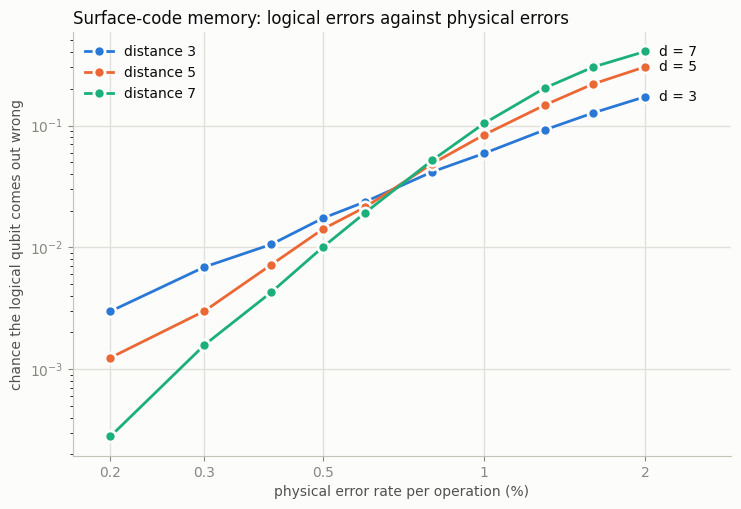

 physical error       d = 3       d = 5       d = 7
           0.2%    2.98e-03    1.24e-03    2.80e-04
           0.3%    6.90e-03    3.00e-03    1.58e-03
           0.4%    1.06e-02    7.20e-03    4.28e-03
           0.5%    1.74e-02    1.42e-02    1.01e-02
           0.6%    2.37e-02    2.14e-02    1.93e-02
           0.8%    4.17e-02    4.86e-02    5.19e-02
           1.0%    5.91e-02    8.39e-02    1.04e-01
           1.3%    9.23e-02    1.48e-01    2.04e-01
           1.6%    1.27e-01    2.20e-01    3.02e-01
           2.0%    1.72e-01    3.03e-01    4.06e-01


In [6]:
from matplotlib.ticker import NullLocator


def logical_error_rate(distance, p, shots):
    """The fraction of shots in which a surface-code memory experiment ends with the wrong logical value."""
    circuit = stim.Circuit.generated(
        'surface_code:rotated_memory_z',
        distance=distance,
        rounds=distance,
        after_clifford_depolarization=p,
        after_reset_flip_probability=p,
        before_measure_flip_probability=p,
        before_round_data_depolarization=p,
    )
    detections, logical_flips = circuit.compile_detector_sampler().sample(shots, separate_observables=True)
    decoder = pymatching.Matching.from_detector_error_model(circuit.detector_error_model(decompose_errors=True))
    predicted_flips = decoder.decode_batch(detections)
    return np.mean(np.any(predicted_flips != logical_flips, axis=1))


physical_rates = [0.002, 0.003, 0.004, 0.005, 0.006, 0.008, 0.010, 0.013, 0.016, 0.020]
distances = [3, 5, 7]
shots = 50_000
logical_rates = {d: [logical_error_rate(d, p, shots) for p in physical_rates] for d in distances}

percent = 100 * np.array(physical_rates)
fig, ax = plt.subplots(figsize=(8.5, 5.5), facecolor='#fcfcfb')
ax.set_facecolor('#fcfcfb')
for d, color in zip(distances, ['#2a78d6', '#eb6834', '#1baf7a']):
    ax.plot(percent, logical_rates[d], color=color, linewidth=2, marker='o', markersize=8,
            markeredgecolor='#fcfcfb', markeredgewidth=2, label=f'distance {d}')
    ax.annotate(f'd = {d}', (percent[-1], logical_rates[d][-1]), xytext=(10, 0),
                textcoords='offset points', va='center', color='#0b0b0b')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(0.17, 2.9)
ax.set_xticks([0.2, 0.3, 0.5, 1, 2], labels=['0.2', '0.3', '0.5', '1', '2'])
ax.xaxis.set_minor_locator(NullLocator())
ax.set_title('Surface-code memory: logical errors against physical errors', loc='left', color='#0b0b0b')
ax.set_xlabel('physical error rate per operation (%)', color='#52514e')
ax.set_ylabel('chance the logical qubit comes out wrong', color='#52514e')
ax.grid(color='#e1e0d9', linewidth=1)
ax.set_axisbelow(True)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
for side in ('left', 'bottom'):
    ax.spines[side].set_color('#c3c2b7')
ax.tick_params(colors='#898781')
ax.legend(frameon=False, labelcolor='#0b0b0b', loc='upper left')
plt.show()

print(f"{'physical error':>15}" + ''.join(f"{'d = ' + str(d):>12}" for d in distances))
for i, p in enumerate(physical_rates):
    print(f'{100 * p:>14.1f}%' + ''.join(f'{logical_rates[d][i]:>12.2e}' for d in distances))

Below a physical error rate of about 0.7% (for this noise model), the distance-7 code makes the fewest logical errors and the distance-3 code the most: a bigger code helps, and it helps more the lower the physical error rate. Above that point the order flips and bigger codes do worse, because a bigger code also has more places for errors to happen. That crossing point is the **threshold**. Hardware has to be below it, and the further below the better. That's why the experimental milestone that matters is showing that a bigger code makes fewer errors ([Google Quantum AI, Nature 2024](https://doi.org/10.1038/s41586-024-08449-y)).

(Thresholds are often quoted as "about 1%"; the exact value depends on the noise model and on the decoder.)

### How big does a code need to be?

Well below threshold, a rule of thumb is that the logical error rate falls like

$$
\epsilon_L \sim \left(\frac{p}{p_{\rm th}}\right)^{(d+1)/2},
$$

so each time the distance grows by 2, the logical error rate drops by another factor of $p/p_{\rm th}$. Suppose the hardware is ten times below threshold, $p/p_{\rm th} = 0.1$. A long calculation might need $\epsilon_L \approx 10^{-10}$ per operation, which takes $(d+1)/2 = 10$, or $d = 19$. A distance-$d$ surface code uses about $2d^2$ physical qubits for each logical qubit ($d^2$ data qubits plus the ones that measure the stabilizers):

In [7]:
approximate_threshold = 0.01 # actually a bit below this, but don't worry
physical_qubit_error = 0.001 # 0.001 is ~typical for modern qubits, improving over time
p_over_threshold = physical_qubit_error / approximate_threshold
print(f'p_over_threshold {p_over_threshold:.3f}')
for d in range(3, 25, 2):
    logical = p_over_threshold ** ((d + 1) / 2)
    print(f'distance {d:2d}: logical error about {logical:.0e}, about {2 * d**2:4d} physical qubits per logical qubit')

p_over_threshold 0.100
distance  3: logical error about 1e-02, about   18 physical qubits per logical qubit
distance  5: logical error about 1e-03, about   50 physical qubits per logical qubit
distance  7: logical error about 1e-04, about   98 physical qubits per logical qubit
distance  9: logical error about 1e-05, about  162 physical qubits per logical qubit
distance 11: logical error about 1e-06, about  242 physical qubits per logical qubit
distance 13: logical error about 1e-07, about  338 physical qubits per logical qubit
distance 15: logical error about 1e-08, about  450 physical qubits per logical qubit
distance 17: logical error about 1e-09, about  578 physical qubits per logical qubit
distance 19: logical error about 1e-10, about  722 physical qubits per logical qubit
distance 21: logical error about 1e-11, about  882 physical qubits per logical qubit
distance 23: logical error about 1e-12, about 1058 physical qubits per logical qubit


At distance 19 that's about 700 physical qubits for each logical qubit, so a computer with a thousand logical qubits needs about a million physical qubits, before counting the "factories" described below.

**Exercise:** Play with the `physical_qubit_error` rate a little bit and see what happens at the different code distances. As a rule of thumb, the logical error rate that starts to get really interesting for actual science applications is around 1e-12, although there are likely useful things we can do at logical error rates as high as 1e-9. Most of the really fancy applications for quantum computing that you read about in the news are likely to require error rates near 1e-15.

## From error correction to fault-tolerant computing

Storing a logical qubit safely is only half the job: we also need to compute with it. The main notebook takes the fault-tolerant gate set for granted, the cheap Clifford gates ($H$, $S$, CNOT) and the expensive $T$. Here is why they cost what they do.

### The Clifford gates are nearly free

* **Pauli gates are never actually run.** An $X$ or $Z$ gate only changes how later measurement results should be read. So the control software keeps a classical record of them, the _Pauli frame_, and flips the meaning of measurement results instead. The corrections that error correction calls for are Pauli gates too, and they are handled the same way.
* **The other Clifford gates can be moved out of the way.** A Clifford gate can be pushed through the rest of the circuit to the end, changing what the later gates and measurements do, without adding any $T$ gates ([Litinski, 2019](https://arxiv.org/abs/1808.02892)).
* What is left to actually run is one special operation for each $T$ gate, plus measurements. That's why a program's cost is its $T$ count.

### Magic states: how a $T$ gate is made

The $T$ gate can't be done directly on an encoded qubit the way the Clifford gates can. Instead, it is _teleported_ in from a specially prepared one-qubit state, the **magic state**

$$
|T\rangle = T|+\rangle = \frac{1}{\sqrt{2}}\left(|0\rangle + e^{i\pi/4}|1\rangle\right).
$$

The recipe uses only Clifford gates and a measurement:

1. Apply a CNOT from your qubit (the control) to the magic state (the target).
2. Measure the magic-state qubit.
3. If the result is 1, apply an $S$ gate to your qubit.

Your qubit now has a $T$ gate applied to it, and the magic state is used up. Let's check it in QASM: we apply $T$ to $|+\rangle$ two ways, directly and with a magic state, and compare. First, the helper that runs QASM programs:

In [8]:
#@title "Python function to read and run QASM strings [Run me!]" { display-mode: "form" }
def run_qasm_string(qasm_str, verbose=True, shots=1024):
    qc = QuantumCircuit.from_qasm_str(qasm_str=qasm_str)
    backend = AerSimulator()
    qc = qiskit.compiler.transpile(qc, backend=backend)
    job = backend.run(qc, shots=shots)
    result = job.result()
    if verbose:
        print(result.get_counts())
    return result

In [9]:
direct_t_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg q[1];
creg out[1];
h q[0];
t q[0];
h q[0];
measure q[0] -> out[0];
"""

magic_t_qasm_str = """
OPENQASM 2.0;
include "qelib1.inc";

qreg q[1];
qreg magic[1];
creg out[1];
creg check[1];
h q[0];                        // our qubit starts as |+>
h magic[0];                    // make the magic state T|+>
t magic[0];
cx q[0],magic[0];              // 1. CNOT onto the magic state
measure magic[0] -> check[0];  // 2. measure it
if(check==1) s q[0];           // 3. if we got 1, fix up with S
h q[0];
measure q[0] -> out[0];
"""

shots = 100_000
direct = run_qasm_string(direct_t_qasm_str, verbose=False, shots=shots).get_counts()
magic = run_qasm_string(magic_t_qasm_str, verbose=False, shots=shots).get_counts()
# Qiskit lists the registers right to left, so each key reads 'check out'
magic_ones = sum(n for key, n in magic.items() if key.split()[1] == '1')
print(f"T applied directly:    chance of 1 = {direct.get('1', 0) / shots:.4f}")
print(f"T from a magic state:  chance of 1 = {magic_ones / shots:.4f}")
print(f"exact:                 chance of 1 = {np.sin(np.pi / 8) ** 2:.4f}")

T applied directly:    chance of 1 = 0.1445
T from a magic state:  chance of 1 = 0.1467
exact:                 chance of 1 = 0.1464


The two agree, up to the random scatter of the shots. The cost has moved: instead of a gate that's hard to do, we need a supply of clean magic states.

### Distillation and $T$ factories

A magic state made directly on the hardware carries the hardware's error, maybe one in a thousand, which is far too noisy for a long calculation. _Distillation_ fixes this: a circuit of Clifford gates takes 15 noisy magic states and, when its checks pass, puts out one much cleaner one, with error about $35\epsilon^3$ if each input had error $\epsilon$ ([Bravyi & Kitaev, 2005](https://arxiv.org/abs/quant-ph/0403025)). Bravyi and Kitaev named these states "magic" because it is "a rather surprising coincidence that one and the same state" both makes the Clifford gates universal and can be purified by Clifford operations alone.

In [10]:
error = 1e-3
for rounds in (1, 2):
    error = 35 * error**3
    print(f'after {rounds} round(s) of 15-to-1 distillation: error about {error:.1e}, '
          f'using {15**rounds} noisy magic states per clean one')

after 1 round(s) of 15-to-1 distillation: error about 3.5e-08, using 15 noisy magic states per clean one
after 2 round(s) of 15-to-1 distillation: error about 1.5e-21, using 225 noisy magic states per clean one


One round turns $10^{-3}$ into $3.5 \times 10^{-8}$, still short of the $10^{-10}$ or so a long calculation needs. A second round overshoots to about $10^{-21}$ and uses 225 noisy states for each clean one; real designs are tuned somewhere in between. A **$T$ factory** is a region of the machine that runs distillation nonstop and does nothing else. The rate at which the factories deliver magic states sets the speed of the whole computer: running time is about the $T$ count divided by the $T$ rate. Factories also take up a large share of the physical qubits.

### Where things stand

Building a fault-tolerant quantum computer means making the physical error rate low enough to be below threshold, then scaling up the surface code (or a similar code) to achieve the desired logical error rate. This is the central engineering challenge of quantum computing today.

Recent milestones:
- Google demonstrated that increasing surface code size reduces logical error rates — the first time this has been achieved experimentally ([Nature, 2024](https://doi.org/10.1038/s41586-024-08449-y)).
- Current devices operate near the threshold, with physical error rates around 0.1–1%.
- With the surface code, a logical qubit good enough for long calculations takes hundreds to a few thousand physical qubits (newer codes may need fewer), so a machine with a thousand logical qubits needs about a million physical qubits, plus its magic-state factories.
- IBM's public roadmap aims for a machine running 100 million gates on 200 logical qubits by 2029, and a billion gates on 2,000 logical qubits in 2033 ([IBM, 2024](https://ibm.com/quantum/assets/IBM_Quantum_Developmen_&_Innovation_Roadmap_Explainer_2024-Update.pdf)).

We are at the beginning of the error-corrected era of quantum computing — and that is a very exciting place to be.